 Predict Uber ride fare: preprocess data, identify outliers, check correlation, train Linear Regression 
and Random Forest Regression, and compare R² and RMSE.

In [1]:
import pandas as pd 
file=r"C:\Users\Sneha\Desktop\BE\sem1\lp3\uber.csv"
df=pd.read_csv(file);
df.head(10)


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5
5,44470845,2011-02-12 02:27:09.0000006,4.9,2011-02-12 02:27:09 UTC,-73.969019,40.755910,-73.969019,40.755910,1
6,48725865,2014-10-12 07:04:00.0000002,24.5,2014-10-12 07:04:00 UTC,-73.961447,40.693965,-73.871195,40.774297,5
7,44195482,2012-12-11 13:52:00.00000029,2.5,2012-12-11 13:52:00 UTC,0.000000,0.000000,0.000000,0.000000,1
8,15822268,2012-02-17 09:32:00.00000043,9.7,2012-02-17 09:32:00 UTC,-73.975187,40.745767,-74.002720,40.743537,1
9,50611056,2012-03-29 19:06:00.000000273,12.5,2012-03-29 19:06:00 UTC,-74.001065,40.741787,-73.963040,40.775012,1


In [2]:
df.shape

(200000, 9)

In [3]:
df.size

1800000

In [4]:
df.describe()

,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,2.000000e+05,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,2.771250e+07,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,1.601382e+07,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382535e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774550e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155530e+07,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  str    
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  str    
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), str(2)
memory usage: 13.7 MB


In [6]:
df.isnull().sum()

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

In [7]:
df.columns

Index(['Unnamed: 0', 'key', 'fare_amount', 'pickup_datetime',
       'pickup_longitude', 'pickup_latitude', 'dropoff_longitude',
       'dropoff_latitude', 'passenger_count'],
      dtype='str')

In [8]:
df.drop("Unnamed: 0",axis=1, inplace= True)

In [9]:
df.columns

Index(['key', 'fare_amount', 'pickup_datetime', 'pickup_longitude',
       'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude',
       'passenger_count'],
      dtype='str')

In [10]:
df.describe()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


In [11]:
df.dropna(inplace=True)

In [12]:
df.isnull().sum()

key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64

In [13]:
df.drop_duplicates(inplace=True)


In [14]:
df["pickup_datetime"]= pd.to_datetime(df["pickup_datetime"], errors="coerce", utc=True)

In [15]:
df.dropna(subset=["pickup_datetime"],inplace=True)
df.shape

(199999, 8)

In [16]:
df = df[
    (df["fare_amount"] > 0) &
    (df["passenger_count"] > 0) &
    (df["passenger_count"] <= 6)
]

In [17]:
df.shape

(199268, 8)

In [18]:
df=df[(df["pickup_latitude"].between(-90,90)) & (df["dropoff_latitude"].between(-90,90)) & 
     (df["pickup_longitude"].between(-180,180)) &
       (df["dropoff_longitude"].between(-180,180)) ]

In [19]:
import numpy as np
def haversine_distance(lat1, lat2, long1, long2):
    lat1=np.radians(lat1)
    lat2=np.radians(lat2)
    long1=np.radians(long1)
    long2=np.radians(long2)

    dlat=lat2-lat1
    dlong=long2-long1

    a=np.sin(dlat/2)**2+np.cos(lat1)*np.cos(lat2)*np.sin(dlong/2)**2
    c=2*np.arcsin(np.sin(np.sqrt(a)))
    return 6371 *c

In [20]:
df["distance"]=haversine_distance(df["pickup_latitude"],df["dropoff_latitude"],df["pickup_longitude"],df["dropoff_longitude"])

In [21]:
#df.drop(["pickup_latitude","dropoff_latitude","pickup_longitude","dropoff_longitude"],axis=1,inplace=True)

In [22]:
df = df[df["distance"] > 0]
df.head()

,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,distance
0,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06+00:00,-73.999817,40.738354,-73.999512,40.723217,1,1.683323
1,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56+00:00,-73.994355,40.728225,-73.994710,40.750325,1,2.457590
2,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00+00:00,-74.005043,40.740770,-73.962565,40.772647,1,5.036377
3,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21+00:00,-73.976124,40.790844,-73.965316,40.803349,3,1.661683
4,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00+00:00,-73.925023,40.744085,-73.973082,40.761247,5,4.475450


In [23]:
df["hour"]=df["pickup_datetime"].dt.hour
df["year"]=df["pickup_datetime"].dt.year
df["month"]=df["pickup_datetime"].dt.month
df["day"]=df["pickup_datetime"].dt.day
df["day_of_week"]=df["pickup_datetime"].dt.day_of_week
#df['distance'] = abs(df['dropoff_latitude'] - df['pickup_latitude']) + abs(df['dropoff_longitude'] - df['pickup_longitude'])

In [24]:
df = df[
    df["pickup_longitude"].between(-75, -72) &
    df["dropoff_longitude"].between(-75, -72) &
    df["pickup_latitude"].between(40, 42) &
    df["dropoff_latitude"].between(40, 42)
]

In [25]:
df.drop("pickup_datetime", axis=1,inplace=True)
df.drop("key",axis=1,inplace=True)
#cols = ['pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude']
#df.drop(cols,axis=1,inplace=True)

In [26]:
df.head()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,distance,hour,year,month,day,day_of_week
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,1.683323,19,2015,5,7,3
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,2.457590,20,2009,7,17,4
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,5.036377,21,2009,8,24,0
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,1.661683,8,2009,6,26,4
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,4.475450,17,2014,8,28,3


In [27]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


<Axes: ylabel='fare_amount'>

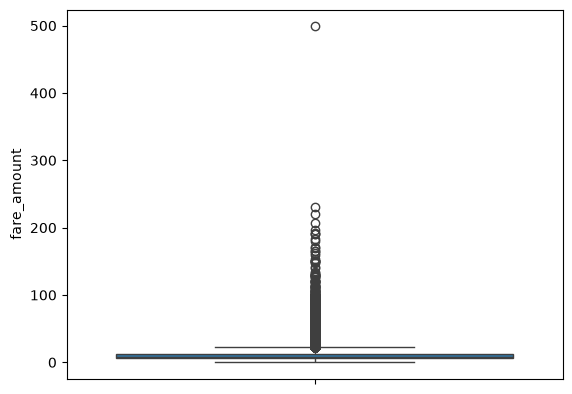

In [28]:
import seaborn as sns

sns.boxplot(y=df["fare_amount"])

In [29]:
q1=df["fare_amount"].quantile(0.25)
q3=df["fare_amount"].quantile(0.75)
iqr=q3-q1
l1=q1-(1.5* iqr)
l2=q3+(1.5*iqr)

df= df[(df["fare_amount"]>=l1) & (df["fare_amount"]<=l2)]

In [30]:
df.shape

(176546, 12)

In [31]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score,root_mean_squared_error



In [32]:
y=df["fare_amount"]
x= df.drop("fare_amount", axis=1)
x_train, x_test, y_train, y_test= train_test_split(x,y, test_size=0.2, random_state=42)


In [33]:
scaler=StandardScaler()

x_train_sc=scaler.fit_transform(x_train)
x_test_sc=scaler.transform(x_test)

model=LinearRegression()
model2=RandomForestRegressor()

model.fit(x_train,y_train)
model2.fit(x_train,y_train)
lr_predictions=model.predict(x_test_sc)
rr_predictions=model2.predict(x_test_sc)

lr_r2=r2_score(y_test,lr_predictions)

lr_rmse=root_mean_squared_error(y_test,lr_predictions)

rr_r2=r2_score(y_test,rr_predictions)

rr_rmse=root_mean_squared_error(y_test,rr_predictions)

c:\Users\Sneha\PROJECTS'2026\acdc\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
c:\Users\Sneha\PROJECTS'2026\acdc\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


In [34]:
print(lr_r2)
print(lr_rmse)
print(rr_r2)
print(rr_rmse)

-36986.39406923751
797.7836821889641
0.1388533894868521
3.84943357663938


In [35]:
print(lr_predictions)

[-776.50141051 -764.02285551 -791.39700755 ... -798.12430694 -793.009794
 -747.24171416]


In [36]:
df.head()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,distance,hour,year,month,day,day_of_week
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,1.683323,19,2015,5,7,3
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,2.457590,20,2009,7,17,4
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,5.036377,21,2009,8,24,0
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,1.661683,8,2009,6,26,4
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,4.475450,17,2014,8,28,3


In [37]:
df.describe()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,distance,hour,year,month,day,day_of_week
count,176546.000000,176546.000000,176546.000000,176546.000000,176546.000000,176546.000000,176546.000000,176546.000000,176546.000000,176546.000000,176546.000000,176546.000000
mean,8.961405,-73.980062,40.752061,-73.978339,40.752305,1.686286,2.548810,13.530037,2011.706292,6.264837,15.705890,3.050570
std,4.138490,0.023958,0.024787,0.024788,0.027160,1.303266,2.100881,6.513290,1.859583,3.444379,8.685693,1.942491
min,0.010000,-74.719883,40.002405,-74.728123,40.005487,1.000000,0.000084,0.000000,2009.000000,1.000000,1.000000,0.000000
25%,5.700000,-73.992615,40.737153,-73.991871,40.736917,1.000000,1.221413,9.000000,2010.000000,3.000000,8.000000,1.000000
50%,8.000000,-73.982552,40.753210,-73.981272,40.753859,1.000000,2.009552,14.000000,2012.000000,6.000000,16.000000,3.000000
75%,11.000000,-73.970415,40.766868,-73.968116,40.767804,2.000000,3.327677,19.000000,2013.000000,9.000000,23.000000,5.000000
max,22.200000,-72.750302,41.366138,-72.759090,41.500000,6.000000,101.675874,23.000000,2015.000000,12.000000,31.000000,6.000000
